# Análise Financeira com Python — ClearBank
Desafio final do módulo de fundamentos de Python aplicados à análise de dados.

Este notebook lê o arquivo `transacoes.csv`, valida e limpa os registros, calcula métricas
financeiras mensais, sinaliza transações suspeitas, exibe um relatório formatado no terminal
e salva o resultado em `relatorio.json`.

**Ordem das células:** constantes → leitura → validação → processamento/datas → geração do
relatório → exportação JSON → exibição → execução principal.

In [1]:
import csv
import json
from datetime import datetime

# Limite acima do qual uma transação é considerada suspeita
LIMITE_SUSPEITO = 10000.00

# Formato de data aceito no arquivo de entrada
FORMATO_DATA = "%Y-%m-%d"


## 1. Leitura do CSV (módulo nativo, sem pandas)

In [2]:
def ler_transacoes(caminho_arquivo):
    """
    Lê o arquivo CSV de transações usando o módulo csv nativo.
    Retorna uma lista de dicionários (uma linha = um dicionário), com os
    valores ainda como texto (a validação/conversão acontece depois).
    Lança FileNotFoundError se o arquivo não existir.
    """
    linhas = []
    try:
        with open(caminho_arquivo, mode="r", encoding="utf-8") as arquivo:
            leitor = csv.DictReader(arquivo)
            for linha in leitor:
                linhas.append(linha)
    except FileNotFoundError:
        print(f"Erro: o arquivo '{caminho_arquivo}' não foi encontrado.")
        raise
    return linhas


In [3]:
# teste rápido
transacoes_brutas = ler_transacoes("transacoes.csv")
print(f"Linhas lidas do arquivo: {len(transacoes_brutas)}")
print("Exemplo de linha bruta:", transacoes_brutas[0])


Linhas lidas do arquivo: 23
Exemplo de linha bruta: {'id': '1', 'data': '2026-01-05', 'cliente_id': 'CLI001', 'tipo': 'credito', 'valor': '3500.00', 'descricao': 'Salário janeiro', 'categoria': 'salario'}


## 2. Validação e limpeza dos dados
Cada linha passa por validações independentes. Qualquer falha descarta a linha
(sem interromper o programa) e é contabilizada nas estatísticas de limpeza.

In [4]:
def validar_data(texto_data):
    """Converte texto para datetime.date. Retorna None se o formato for inválido."""
    try:
        return datetime.strptime(texto_data, FORMATO_DATA).date()
    except (ValueError, TypeError):
        return None


def validar_valor(texto_valor):
    """Converte texto para float e garante que seja > 0. Retorna None se inválido."""
    try:
        valor = float(texto_valor)
    except (ValueError, TypeError):
        return None
    if valor <= 0:
        return None
    return valor


def validar_transacao(linha):
    """
    Valida uma única linha do CSV.
    Retorna o registro limpo (dict com tipos corretos) se válido,
    ou None se a linha deve ser descartada.
    """
    id_texto = (linha.get("id") or "").strip()
    cliente_id = (linha.get("cliente_id") or "").strip()
    tipo = (linha.get("tipo") or "").strip().lower()
    descricao = (linha.get("descricao") or "").strip()
    categoria = (linha.get("categoria") or "").strip()

    if not id_texto.isdigit():
        return None
    if not cliente_id:
        return None
    if tipo not in ("credito", "debito"):
        return None

    data = validar_data((linha.get("data") or "").strip())
    if data is None:
        return None

    valor = validar_valor((linha.get("valor") or "").strip())
    if valor is None:
        return None

    return {
        "id": int(id_texto),
        "data": data,
        "mes": data.strftime("%Y-%m"),
        "cliente_id": cliente_id,
        "tipo": tipo,
        "valor": valor,
        "descricao": descricao,
        "categoria": categoria,
        "suspeita": valor > LIMITE_SUSPEITO,
    }


In [5]:
# teste rápido com uma linha válida e uma inválida
print(validar_transacao({"id": "1", "data": "2026-01-05", "cliente_id": "CLI001",
                          "tipo": "credito", "valor": "3500.00",
                          "descricao": "Salário", "categoria": "salario"}))
print(validar_transacao({"id": "4", "data": "2026-02/03", "cliente_id": "",
                          "tipo": "debito", "valor": "abc",
                          "descricao": "Sem cliente", "categoria": "transferencia"}))


{'id': 1, 'data': datetime.date(2026, 1, 5), 'mes': '2026-01', 'cliente_id': 'CLI001', 'tipo': 'credito', 'valor': 3500.0, 'descricao': 'Salário', 'categoria': 'salario', 'suspeita': False}
None


## 3. Processamento geral: separa válidas/inválidas e calcula o intervalo de datas

In [6]:
def processar_transacoes(linhas_brutas):
    """
    Aplica validar_transacao() em cada linha, separando as válidas das
    inválidas, e calcula o período coberto pelos dados (data mais antiga
    e mais recente).
    """
    validas = []
    total_invalidas = 0

    for linha in linhas_brutas:
        registro = validar_transacao(linha)
        if registro is None:
            total_invalidas += 1
        else:
            validas.append(registro)

    if validas:
        data_mais_antiga = min(t["data"] for t in validas)
        data_mais_recente = max(t["data"] for t in validas)
        dias_periodo = (data_mais_recente - data_mais_antiga).days
    else:
        data_mais_antiga = data_mais_recente = None
        dias_periodo = 0

    return {
        "validas": validas,
        "total_lidas": len(linhas_brutas),
        "total_validas": len(validas),
        "total_invalidas": total_invalidas,
        "data_mais_antiga": data_mais_antiga,
        "data_mais_recente": data_mais_recente,
        "dias_periodo": dias_periodo,
    }


In [7]:
resultado_processamento = processar_transacoes(transacoes_brutas)
print(f"Total de linhas lidas: {resultado_processamento['total_lidas']}")
print(f"Linhas válidas: {resultado_processamento['total_validas']}")
print(f"Linhas inválidas: {resultado_processamento['total_invalidas']}")
print(f"Período: {resultado_processamento['data_mais_antiga']} -> "
      f"{resultado_processamento['data_mais_recente']} "
      f"({resultado_processamento['dias_periodo']} dias)")


Total de linhas lidas: 23
Linhas válidas: 18
Linhas inválidas: 5
Período: 2026-01-05 -> 2026-04-10 (95 dias)


## 4. Agrupamento mensal, métricas e transações suspeitas

In [8]:
def gerar_relatorio(transacoes_validas):
    """
    Agrupa as transações válidas por mês (AAAA-MM) e calcula, para cada mês:
    quantidade, total de crédito, total de débito, saldo, média, maior e
    menor valor. Também monta a lista de transações suspeitas.
    """
    resumo_mensal = {}

    for transacao in transacoes_validas:
        mes = transacao["mes"]
        if mes not in resumo_mensal:
            resumo_mensal[mes] = {
                "quantidade": 0,
                "total_credito": 0.0,
                "total_debito": 0.0,
                "maior_valor": None,
                "menor_valor": None,
            }

        dados_mes = resumo_mensal[mes]
        dados_mes["quantidade"] += 1

        if transacao["tipo"] == "credito":
            dados_mes["total_credito"] += transacao["valor"]
        else:
            dados_mes["total_debito"] += transacao["valor"]

        if dados_mes["maior_valor"] is None or transacao["valor"] > dados_mes["maior_valor"]:
            dados_mes["maior_valor"] = transacao["valor"]
        if dados_mes["menor_valor"] is None or transacao["valor"] < dados_mes["menor_valor"]:
            dados_mes["menor_valor"] = transacao["valor"]

    # calcula saldo e média depois de somar tudo
    for mes, dados_mes in resumo_mensal.items():
        dados_mes["saldo"] = dados_mes["total_credito"] - dados_mes["total_debito"]
        dados_mes["media"] = (
            (dados_mes["total_credito"] + dados_mes["total_debito"]) / dados_mes["quantidade"]
            if dados_mes["quantidade"] else 0.0
        )

    transacoes_suspeitas = [t for t in transacoes_validas if t["suspeita"]]
    transacoes_suspeitas.sort(key=lambda t: t["data"])

    return resumo_mensal, transacoes_suspeitas


In [9]:
resumo_mensal, transacoes_suspeitas = gerar_relatorio(resultado_processamento["validas"])
print("Meses encontrados:", list(resumo_mensal.keys()))
print("Transações suspeitas encontradas:", len(transacoes_suspeitas))


Meses encontrados: ['2026-01', '2026-02', '2026-03', '2026-04']
Transações suspeitas encontradas: 2


## 5. Exportação do relatório em JSON

In [10]:
def salvar_json(caminho_arquivo, resultado_processamento, resumo_mensal, transacoes_suspeitas):
    """Monta a estrutura final do relatório e salva em disco como JSON."""
    resumo_mensal_formatado = {}
    for mes, dados_mes in sorted(resumo_mensal.items()):
        resumo_mensal_formatado[mes] = {
            "quantidade": dados_mes["quantidade"],
            "total_credito": round(dados_mes["total_credito"], 2),
            "total_debito": round(dados_mes["total_debito"], 2),
            "saldo": round(dados_mes["saldo"], 2),
            "media": round(dados_mes["media"], 2),
            "maior_valor": round(dados_mes["maior_valor"], 2),
            "menor_valor": round(dados_mes["menor_valor"], 2),
        }

    relatorio = {
        "gerado_em": datetime.now().strftime("%Y-%m-%d"),
        "total_transacoes_validas": resultado_processamento["total_validas"],
        "total_transacoes_invalidas": resultado_processamento["total_invalidas"],
        "periodo": {
            "data_mais_antiga": str(resultado_processamento["data_mais_antiga"]),
            "data_mais_recente": str(resultado_processamento["data_mais_recente"]),
            "dias": resultado_processamento["dias_periodo"],
        },
        "resumo_mensal": resumo_mensal_formatado,
        "transacoes_suspeitas": [
            {
                "id": t["id"],
                "cliente_id": t["cliente_id"],
                "data": str(t["data"]),
                "valor": round(t["valor"], 2),
            }
            for t in transacoes_suspeitas
        ],
    }

    try:
        with open(caminho_arquivo, mode="w", encoding="utf-8") as arquivo:
            json.dump(relatorio, arquivo, ensure_ascii=False, indent=2)
    except OSError as erro:
        print(f"Erro ao salvar o relatório: {erro}")
        raise

    return relatorio


## 6. Exibição formatada no terminal

In [11]:
def formatar_moeda(valor):
    """Formata um número para o padrão monetário brasileiro: R$ 1.234,56."""
    texto = f"{valor:,.2f}"
    texto = texto.replace(",", "X").replace(".", ",").replace("X", ".")
    return f"R$ {texto}"


def exibir_relatorio(resultado_processamento, resumo_mensal, transacoes_suspeitas):
    """Imprime o relatório completo, formatado, no terminal."""
    print("=" * 50)
    print("RELATÓRIO FINANCEIRO - CLEARBANK")
    print("=" * 50)
    print(f"Período analisado: {resultado_processamento['data_mais_antiga']} -> "
          f"{resultado_processamento['data_mais_recente']} "
          f"({resultado_processamento['dias_periodo']} dias)")
    print(f"Total de transações válidas:   {resultado_processamento['total_validas']}")
    print(f"Total de transações inválidas: {resultado_processamento['total_invalidas']}")

    print()
    print("===== RELATÓRIO MENSAL =====")
    for mes, dados_mes in sorted(resumo_mensal.items()):
        print()
        print(f"Mês: {mes}")
        print(f"  Transações: {dados_mes['quantidade']}")
        print(f"  Total crédito: {formatar_moeda(dados_mes['total_credito'])}")
        print(f"  Total débito:  {formatar_moeda(dados_mes['total_debito'])}")
        print(f"  Saldo:         {formatar_moeda(dados_mes['saldo'])}")
        print(f"  Média:         {formatar_moeda(dados_mes['media'])}")
        print(f"  Maior valor:   {formatar_moeda(dados_mes['maior_valor'])}")
        print(f"  Menor valor:   {formatar_moeda(dados_mes['menor_valor'])}")

    print()
    print("===== TRANSAÇÕES SUSPEITAS =====")
    if transacoes_suspeitas:
        for t in transacoes_suspeitas:
            print(f"ID: {t['id']} | Cliente: {t['cliente_id']} | "
                  f"Data: {t['data']} | Valor: {formatar_moeda(t['valor'])}")
    else:
        print("Nenhuma transação suspeita encontrada.")
    print("=" * 50)


## 7. Célula de execução principal
Executa o pipeline completo: leitura → processamento → relatório → JSON → exibição.
Use esta célula como validação final depois de implementar tudo acima.

In [12]:
ARQUIVO_ENTRADA = "transacoes.csv"
ARQUIVO_SAIDA = "relatorio.json"

transacoes_brutas = ler_transacoes(ARQUIVO_ENTRADA)
resultado_processamento = processar_transacoes(transacoes_brutas)
resumo_mensal, transacoes_suspeitas = gerar_relatorio(resultado_processamento["validas"])
relatorio_final = salvar_json(ARQUIVO_SAIDA, resultado_processamento, resumo_mensal, transacoes_suspeitas)
exibir_relatorio(resultado_processamento, resumo_mensal, transacoes_suspeitas)

print()
print(f"Relatório salvo em '{ARQUIVO_SAIDA}'.")


RELATÓRIO FINANCEIRO - CLEARBANK
Período analisado: 2026-01-05 -> 2026-04-10 (95 dias)
Total de transações válidas:   18
Total de transações inválidas: 5

===== RELATÓRIO MENSAL =====

Mês: 2026-01
  Transações: 5
  Total crédito: R$ 7.700,00
  Total débito:  R$ 595,80
  Saldo:         R$ 7.104,20
  Média:         R$ 1.659,16
  Maior valor:   R$ 4.200,00
  Menor valor:   R$ 95,30

Mês: 2026-02
  Transações: 6
  Total crédito: R$ 34.000,00
  Total débito:  R$ 620,65
  Saldo:         R$ 33.379,35
  Média:         R$ 5.770,11
  Maior valor:   R$ 15.500,00
  Menor valor:   R$ 89,90

Mês: 2026-03
  Transações: 5
  Total crédito: R$ 7.700,00
  Total débito:  R$ 699,90
  Saldo:         R$ 7.000,10
  Média:         R$ 1.679,98
  Maior valor:   R$ 4.200,00
  Menor valor:   R$ 99,90

Mês: 2026-04
  Transações: 2
  Total crédito: R$ 3.500,00
  Total débito:  R$ 610,40
  Saldo:         R$ 2.889,60
  Média:         R$ 2.055,20
  Maior valor:   R$ 3.500,00
  Menor valor:   R$ 610,40

===== TRANSAÇÕE

---
## Requisito opcional (RO2): gráfico com matplotlib
Gera `grafico.png` com o saldo mensal (crédito − débito por mês).

Gráfico salvo em 'grafico.png'.


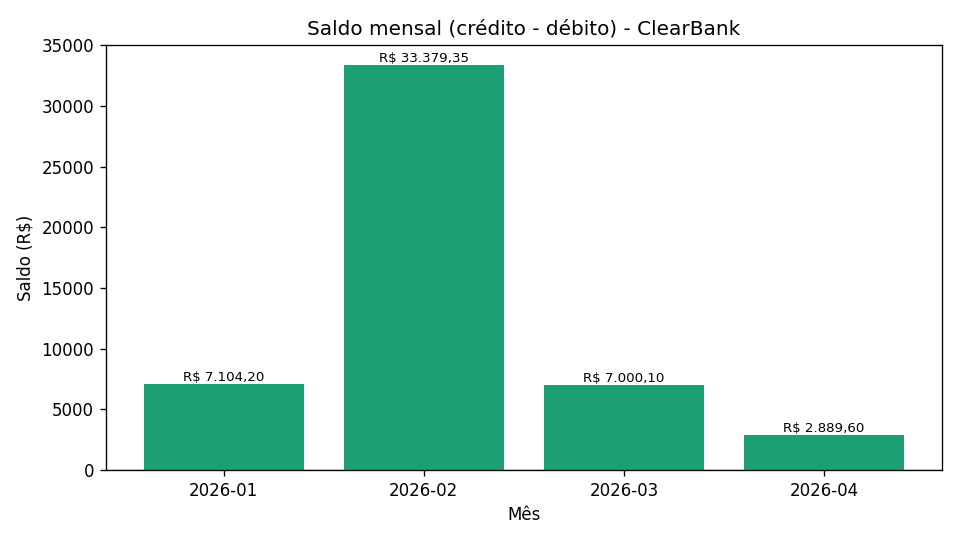

In [13]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

meses = sorted(resumo_mensal.keys())
saldos = [resumo_mensal[m]["saldo"] for m in meses]
cores = ["#1D9E75" if s >= 0 else "#D85A30" for s in saldos]

plt.figure(figsize=(8, 4.5))
plt.bar(meses, saldos, color=cores)
plt.title("Saldo mensal (crédito - débito) - ClearBank")
plt.xlabel("Mês")
plt.ylabel("Saldo (R$)")
plt.axhline(0, color="#888780", linewidth=0.8)
for i, s in enumerate(saldos):
    plt.text(i, s, formatar_moeda(s), ha="center",
              va="bottom" if s >= 0 else "top", fontsize=8)
plt.tight_layout()
plt.savefig("grafico.png", dpi=120)
plt.show()
print("Gráfico salvo em 'grafico.png'.")
